# Model 1 — Logistic Regression (L2) × 3 Imbalance Strategies

**Owner**: Ayaan
**Inputs** (from Leonie's `02_data_preprocessing.ipynb`): `data/processed/train_raw.csv` (with shared `cv_fold` 0–4), `data/processed/test_raw.csv`, `data/processed/metadata.json`
**Outputs** (for Tanish): `results/logreg_A.npz`, `results/logreg_B.npz`, `results/logreg_C.npz`

| Strategy | What changes | Implementation |
|---|---|---|
| **A — Do Nothing** | Train on the original 88.7% / 11.3% data, uniform weights | `LogisticRegression()` |
| **B — Class Weighting** | Minority errors cost ~7.88× more | `LogisticRegression(class_weight="balanced")` |
| **C — Resample (SMOTE)** | Training data oversampled to 1:1 | `imblearn` `Pipeline(prep → SMOTE → LogisticRegression)` |

**Leakage-free protocol**
- Hyperparameter `C` (inverse L2 strength) is tuned with **5-fold stratified CV on the training set only**, using the team's shared `cv_fold` IDs (`PredefinedSplit`), scored by **PR-AUC (average precision)**.
- `StandardScaler` + `OneHotEncoder` (and SMOTE for Strategy C) live **inside** an `imblearn.pipeline.Pipeline`, so they are re-fit on the 4 training folds of every split and never see the validation fold. SMOTE is never applied to validation or test data.
- The **test set is touched exactly once per strategy**, after tuning, to produce the exported predictions.

**Output contract (each `.npz`)**: `y_test_prob`, `y_test_pred` (threshold 0.5), `y_test`, `train_time_sec` (final `.fit()` of the classifier only), `resample_time_sec`, `n_train_samples`, `best_params` (JSON string), `cv_pr_auc_mean/std`, plus out-of-fold CV probabilities `cv_oof_prob` / `cv_oof_y` (for Tanish's optional threshold-tuning comparison).

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, PredefinedSplit, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set DEBUG = True to run end-to-end on the 10% debug file (fast); False for the real experiment.
DEBUG = False

RANDOM_STATE = 42
MODEL_NAME = "logreg"
STRATEGY_NAMES = {"A": "Do Nothing", "B": "Class Weighting", "C": "SMOTE (1:1)"}
C_GRID = np.logspace(-4, 2, 13)  # 1e-4 ... 1e2

ROOT_DIR = Path(".") if Path("data/processed").exists() else Path("..")
PROC_DIR = ROOT_DIR / "data" / "processed"
RESULTS_DIR = ROOT_DIR / "results" / ("debug" if DEBUG else "")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(PROC_DIR / "metadata.json") as f:
    META = json.load(f)
NUMERIC_COLS, BINARY_COLS, CATEGORICAL_COLS = META["numeric_cols"], META["binary_cols"], META["categorical_cols"]
FEATURE_COLS = NUMERIC_COLS + BINARY_COLS + CATEGORICAL_COLS

prefix = "debug_" if DEBUG else ""
train_raw = pd.read_csv(PROC_DIR / f"{prefix}train_raw.csv")
test_raw = pd.read_csv(PROC_DIR / f"{prefix}test_raw.csv")

X_train_raw, y_train = train_raw[FEATURE_COLS], train_raw["y"].to_numpy()
X_test_raw, y_test = test_raw[FEATURE_COLS], test_raw["y"].to_numpy()
cv_split = PredefinedSplit(train_raw["cv_fold"].to_numpy())  # shared team folds 0..4

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

print(f"Mode: {'DEBUG (10%)' if DEBUG else 'FULL'}")
print(f"Train: {len(y_train):,} rows ({y_train.mean():.2%} yes) | Test: {len(y_test):,} rows ({y_test.mean():.2%} yes)")
print(f"CV folds: {cv_split.get_n_splits()} | Results -> {RESULTS_DIR.resolve()}")

Mode: FULL
Train: 32,940 rows (11.27% yes) | Test: 8,236 rows (11.27% yes)
CV folds: 5 | Results -> /Users/ayaankukreja/Documents/Bank_Marketing/results


### Shared helpers
`build_preprocessor()` is the same `ColumnTransformer` Leonie defined (StandardScaler on numeric, passthrough on `was_previously_contacted`, OneHotEncoder keeping `"unknown"` as a category). It is rebuilt here because `preprocessor.joblib` was pickled with scikit-learn 0.23 and does not load on newer versions; the cell below checks that it reproduces `processed_arrays.npz` exactly.

In [2]:
def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERIC_COLS),
            ("bin", "passthrough", BINARY_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
        ],
        remainder="drop",
    )


def build_pipeline(strategy, C=1.0):
    """prep -> [SMOTE if C] -> LogisticRegression. Every step is fit on training folds only."""
    steps = [("prep", build_preprocessor())]
    if strategy == "C":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    clf = LogisticRegression(
        C=C,
        l1_ratio=0,  # pure L2 penalty (sklearn >= 1.8 API; the old `penalty="l2"` is deprecated)
        class_weight="balanced" if strategy == "B" else None,
        solver="lbfgs",
        max_iter=5000,
        random_state=RANDOM_STATE,
    )
    steps.append(("clf", clf))
    return Pipeline(steps)


def quick_metrics(y_true, y_prob, threshold=0.5):
    """Own sanity check only; Tanish's evaluation script produces the official numbers."""
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "PR-AUC": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Brier": brier_score_loss(y_true, y_prob),
        "FP (wasted calls)": int(((y_pred == 1) & (y_true == 0)).sum()),
        "TP": int(((y_pred == 1) & (y_true == 1)).sum()),
    }


def save_results(strategy, y_prob, train_time_sec, resample_time_sec, n_train_samples,
                 best_params, cv_mean, cv_std, oof_prob, extra=None):
    path = RESULTS_DIR / f"{MODEL_NAME}_{strategy}.npz"
    np.savez(
        path,
        model=MODEL_NAME,
        strategy=strategy,
        strategy_name=STRATEGY_NAMES[strategy],
        y_test=y_test.astype(np.int64),
        y_test_prob=y_prob.astype(np.float64),
        y_test_pred=(y_prob >= 0.5).astype(np.int64),
        train_time_sec=float(train_time_sec),
        resample_time_sec=float(resample_time_sec),
        n_train_samples=int(n_train_samples),
        best_params=json.dumps(best_params),
        cv_pr_auc_mean=float(cv_mean),
        cv_pr_auc_std=float(cv_std),
        cv_oof_prob=oof_prob.astype(np.float64),
        cv_oof_y=y_train.astype(np.int64),
        extra=json.dumps(extra or {}),
    )
    print(f"Saved -> {path}")


# Consistency check against Leonie's shared processed arrays (full mode only)
if not DEBUG:
    shared = np.load(PROC_DIR / "processed_arrays.npz")
    _prep = build_preprocessor().fit(X_train_raw)
    assert np.allclose(_prep.transform(X_train_raw), shared["X_train"], atol=1e-5)
    assert np.allclose(_prep.transform(X_test_raw), shared["X_test"], atol=1e-5)
    assert (shared["y_test"] == y_test).all()
    FEATURE_NAMES = META["transformed_feature_names"]
    print("Preprocessor reproduces processed_arrays.npz exactly.")
else:
    FEATURE_NAMES = list(build_preprocessor().fit(X_train_raw).get_feature_names_out())

Preprocessor reproduces processed_arrays.npz exactly.


### Tune → refit → export (one function, run once per strategy)
1. `GridSearchCV` over `C` with the shared folds, scoring PR-AUC (threshold-free and the right headline metric at 11% positives).
2. Out-of-fold probabilities for the best `C` (same folds) are kept for threshold-tuning analysis.
3. Final refit on the **full training set**. `train_time_sec` times only `LogisticRegression.fit()`; SMOTE time is recorded separately as `resample_time_sec` so the compute cost of resampling is visible on its own.
4. Predict the locked test set once and save.

In [3]:
CV_TABLES, SUMMARY, FINAL_MODELS = {}, {}, {}


def run_strategy(strategy):
    print(f"=== Strategy {strategy}: {STRATEGY_NAMES[strategy]} ===")

    # 1. Tune C with leakage-free 5-fold CV
    t0 = time.perf_counter()
    search = GridSearchCV(
        build_pipeline(strategy),
        param_grid={"clf__C": C_GRID},
        scoring="average_precision",
        cv=cv_split,
        n_jobs=-1,
        refit=False,
        return_train_score=True,
    )
    search.fit(X_train_raw, y_train)
    cv_time = time.perf_counter() - t0

    cv_table = pd.DataFrame({
        "C": C_GRID,
        "cv_pr_auc_mean": search.cv_results_["mean_test_score"],
        "cv_pr_auc_std": search.cv_results_["std_test_score"],
        "train_pr_auc_mean": search.cv_results_["mean_train_score"],
    })
    CV_TABLES[strategy] = cv_table
    best_idx = search.best_index_
    best_C = float(search.best_params_["clf__C"])
    cv_mean, cv_std = cv_table.loc[best_idx, ["cv_pr_auc_mean", "cv_pr_auc_std"]]
    print(f"Best C = {best_C:.4g} | CV PR-AUC = {cv_mean:.4f} ± {cv_std:.4f} | tuning time {cv_time:.1f}s")

    # 2. Out-of-fold probabilities at best C (for threshold tuning on validation data, never test)
    oof_prob = cross_val_predict(build_pipeline(strategy, best_C), X_train_raw, y_train,
                                 cv=cv_split, method="predict_proba", n_jobs=-1)[:, 1]

    # 3. Final fit on the full training set (steps run manually to time them separately)
    final = build_pipeline(strategy, best_C)
    X_fit = final.named_steps["prep"].fit_transform(X_train_raw)
    y_fit = y_train
    resample_time = 0.0
    if strategy == "C":
        t0 = time.perf_counter()
        X_fit, y_fit = final.named_steps["smote"].fit_resample(X_fit, y_fit)
        resample_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    final.named_steps["clf"].fit(X_fit, y_fit)
    train_time = time.perf_counter() - t0

    # 4. Predict locked test set once
    y_prob = final.predict_proba(X_test_raw)[:, 1]
    FINAL_MODELS[strategy] = final

    best_params = {"C": best_C, "penalty": "l2", "solver": "lbfgs",
                   "class_weight": "balanced" if strategy == "B" else None,
                   "smote": strategy == "C"}
    save_results(strategy, y_prob, train_time, resample_time, len(y_fit), best_params,
                 cv_mean, cv_std, oof_prob, extra={"cv_time_sec": cv_time})

    SUMMARY[strategy] = {"Strategy": f"{strategy}: {STRATEGY_NAMES[strategy]}", "Best C": best_C,
                         "CV PR-AUC": cv_mean, "n_train": len(y_fit),
                         "Train time (s)": train_time, "Resample time (s)": resample_time,
                         **quick_metrics(y_test, y_prob)}
    print(f"n_train = {len(y_fit):,} ({y_fit.mean():.1%} yes) | fit {train_time:.2f}s | "
          f"test PR-AUC {SUMMARY[strategy]['PR-AUC']:.4f}\n")
    return cv_table

# DO NOTHING
**Strategy A** — original class balance, uniform sample weights.

In [4]:
run_strategy("A").round(4)

=== Strategy A: Do Nothing ===


Best C = 3.162 | CV PR-AUC = 0.4506 ± 0.0140 | tuning time 14.2s


Saved -> ../results/logreg_A.npz
n_train = 32,940 (11.3% yes) | fit 0.14s | test PR-AUC 0.4536



,C,cv_pr_auc_mean,cv_pr_auc_std,train_pr_auc_mean
0,0.0001,0.3905,0.0150,0.3899
1,0.0003,0.4032,0.0150,0.4033
2,0.0010,0.4198,0.0154,0.4205
3,0.0032,0.4332,0.0167,0.4348
4,0.0100,0.4440,0.0171,0.4470
5,0.0316,0.4485,0.0157,0.4530
6,0.1000,0.4502,0.0142,0.4563
7,0.3162,0.4506,0.0140,0.4576
8,1.0000,0.4506,0.0141,0.4580
9,3.1623,0.4506,0.0140,0.4580


# CLASS WEIGHTING
**Strategy B** — `class_weight="balanced"` gives each `yes` a weight of n/(2·n_yes) and each `no` n/(2·n_no), i.e. a minority-to-majority weight ratio of n_no/n_yes ≈ 7.88 (recomputed on each training fold). The training set size is unchanged.

In [5]:
run_strategy("B").round(4)

=== Strategy B: Class Weighting ===


Best C = 1 | CV PR-AUC = 0.4462 ± 0.0129 | tuning time 15.2s


Saved -> ../results/logreg_B.npz
n_train = 32,940 (11.3% yes) | fit 0.18s | test PR-AUC 0.4466



,C,cv_pr_auc_mean,cv_pr_auc_std,train_pr_auc_mean
0,0.0001,0.3992,0.0146,0.3990
1,0.0003,0.4142,0.0153,0.4148
2,0.0010,0.4247,0.0161,0.4256
3,0.0032,0.4321,0.0159,0.4340
4,0.0100,0.4400,0.0156,0.4427
5,0.0316,0.4446,0.0136,0.4484
6,0.1000,0.4459,0.0131,0.4513
7,0.3162,0.4460,0.0133,0.4522
8,1.0000,0.4462,0.0129,0.4523
9,3.1623,0.4460,0.0131,0.4523


# RESAMPLE TRAINING DATA
**Strategy C** — SMOTE (k=5) creates synthetic `yes` rows by interpolating between scaled/encoded minority neighbours until the training data is 1:1. It runs **after** preprocessing (so distances are on standardized features) and **only on training folds**.

> Note for the report: standard SMOTE on one-hot columns produces fractional category values (e.g. `job_student = 0.4`) on synthetic rows. Logistic regression treats them as continuous inputs, so this is a modelling approximation rather than a bug; SMOTENC would avoid it at higher compute cost.

In [6]:
run_strategy("C").round(4)

=== Strategy C: SMOTE (1:1) ===


Best C = 0.3162 | CV PR-AUC = 0.4433 ± 0.0150 | tuning time 24.5s


Saved -> ../results/logreg_C.npz
n_train = 58,458 (50.0% yes) | fit 0.49s | test PR-AUC 0.4452



,C,cv_pr_auc_mean,cv_pr_auc_std,train_pr_auc_mean
0,0.0001,0.4079,0.0154,0.4083
1,0.0003,0.4209,0.0167,0.4215
2,0.0010,0.4279,0.0176,0.4300
3,0.0032,0.4355,0.0179,0.4381
4,0.0100,0.4408,0.0156,0.4446
5,0.0316,0.4420,0.0150,0.4479
6,0.1000,0.4432,0.0152,0.4497
7,0.3162,0.4433,0.0150,0.4501
8,1.0000,0.4432,0.0151,0.4501
9,3.1623,0.4431,0.0152,0.4500


---
# Summary
### Regularization path: CV PR-AUC vs. C

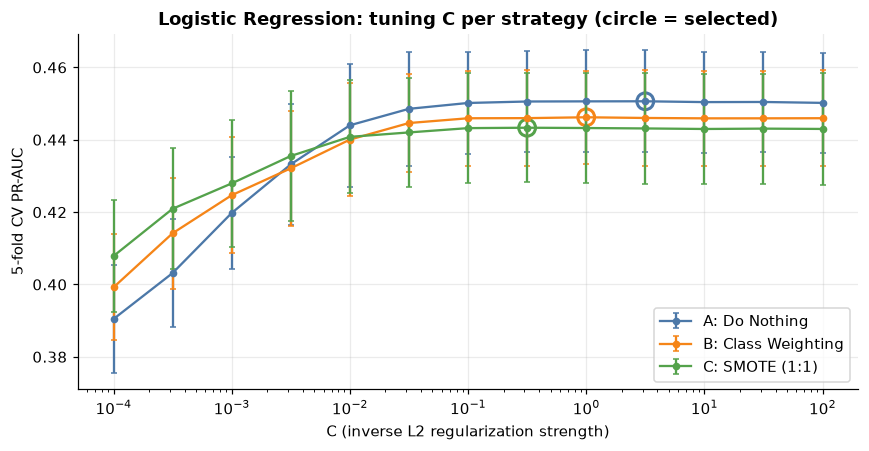

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = {"A": "#4C78A8", "B": "#F58518", "C": "#54A24B"}
for s, tbl in CV_TABLES.items():
    ax.errorbar(tbl["C"], tbl["cv_pr_auc_mean"], yerr=tbl["cv_pr_auc_std"], marker="o", ms=4,
                capsize=2, color=colors[s], label=f"{s}: {STRATEGY_NAMES[s]}")
    b = tbl["cv_pr_auc_mean"].idxmax()
    ax.scatter(tbl.loc[b, "C"], tbl.loc[b, "cv_pr_auc_mean"], s=120, facecolors="none", edgecolors=colors[s], lw=2)
ax.set_xscale("log")
ax.set_xlabel("C (inverse L2 regularization strength)")
ax.set_ylabel("5-fold CV PR-AUC")
ax.set_title("Logistic Regression: tuning C per strategy (circle = selected)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

### Test-set sanity check (official comparison is in Tanish's evaluation)

In [8]:
summary_df = pd.DataFrame(SUMMARY.values()).set_index("Strategy")
summary_df.round(4)

,Best C,CV PR-AUC,n_train,Train time (s),Resample time (s),PR-AUC,ROC-AUC,F1,Precision,Recall,Brier,FP (wasted calls),TP
Strategy,,,,,,,,,,,,,
A: Do Nothing,3.1623,0.4506,32940,0.1412,0.0000,0.4536,0.8003,0.3182,0.6447,0.2112,0.0779,108,196
B: Class Weighting,1.0000,0.4462,32940,0.1831,0.0000,0.4466,0.8001,0.4613,0.3589,0.6455,0.1620,1070,599
C: SMOTE (1:1),0.3162,0.4433,58458,0.4919,0.0893,0.4452,0.7992,0.4546,0.3478,0.6562,0.1619,1142,609


### Coefficients (largest |β| on standardized features)
The macro indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) are highly correlated (r ≈ 0.91–0.97), so their individual coefficients can be large and of opposite sign — interpret them as a group, not one by one.

In [9]:
coef_df = pd.DataFrame({s: m.named_steps["clf"].coef_.ravel() for s, m in FINAL_MODELS.items()},
                       index=FEATURE_NAMES)
top = coef_df["A"].abs().sort_values(ascending=False).head(15).index
coef_df.loc[top].rename(columns=lambda s: f"β ({s})").round(3)

,β (A),β (B),β (C)
emp.var.rate,-2.263,-2.260,-2.543
was_previously_contacted,1.360,1.416,1.190
month_mar,1.287,1.285,1.394
cons.price.idx,1.189,1.134,1.398
month_jun,-0.826,-0.809,-0.905
contact_telephone,-0.676,-0.349,-0.582
month_nov,-0.610,-0.564,-0.583
month_may,-0.604,-0.640,-0.481
poutcome_failure,-0.567,-0.354,-0.463
nr.employed,0.504,0.407,0.723


### Export check

In [10]:
for s in ["A", "B", "C"]:
    r = np.load(RESULTS_DIR / f"{MODEL_NAME}_{s}.npz")
    assert r["y_test_prob"].shape == r["y_test_pred"].shape == (len(y_test),)
    assert r["cv_oof_prob"].shape == (len(y_train),)
    print(f"{MODEL_NAME}_{s}.npz | n_train={int(r['n_train_samples']):,} | train_time={float(r['train_time_sec']):.2f}s "
          f"| best_params={r['best_params']}")

logreg_A.npz | n_train=32,940 | train_time=0.14s | best_params={"C": 3.1622776601683795, "penalty": "l2", "solver": "lbfgs", "class_weight": null, "smote": false}
logreg_B.npz | n_train=32,940 | train_time=0.18s | best_params={"C": 1.0, "penalty": "l2", "solver": "lbfgs", "class_weight": "balanced", "smote": false}
logreg_C.npz | n_train=58,458 | train_time=0.49s | best_params={"C": 0.31622776601683794, "penalty": "l2", "solver": "lbfgs", "class_weight": null, "smote": true}


---
## Findings (for the report)

1. **Ranking quality is essentially unchanged by either fix.** Test PR-AUC: A 0.454, B 0.447, C 0.445 (ROC-AUC ≈ 0.80 for all three). CV PR-AUC (0.451 / 0.446 / 0.443) tracks test closely, so there is no sign of leakage. For a linear model, class weighting and SMOTE mostly shift the intercept, which moves the decision threshold rather than improving how customers are ranked.
2. **What B and C buy at the default 0.5 threshold is recall, paid for in wasted calls.**
   - A finds 196 of 928 subscribers (recall 21%, precision 64%, 108 false positives).
   - B finds 599 (recall 65%, precision 36%, 1,070 FPs): **+403 subscribers for +962 extra calls, ≈ 2.4 wasted calls per extra subscriber.**
   - C finds 609 (recall 66%, precision 35%, 1,142 FPs): ≈ 2.5 wasted calls per extra subscriber, slightly worse than B.
3. **Calibration cost.** Brier score roughly doubles (0.078 → 0.162 for both B and C): their probabilities are pushed toward 50% and no longer reflect the true ~11% subscription rate, so they can't be read as "chance this customer says yes" without recalibration.
4. **Compute / data cost.** B is free (same 32,940 rows, fit 0.18 s vs 0.14 s). C trains on 58,458 rows (+77%), fits ~3.5× slower (0.49 s) plus 0.09 s for SMOTE, and CV tuning takes ~1.7× longer. Absolute times are tiny for LR, but the relative cost carries over to heavier models.
5. **Regularization barely matters.** CV PR-AUC is flat for C ≥ 0.1 in all strategies (n/p ≈ 520), so the selected C values (3.16 / 1 / 0.32) are near-equivalent; very strong regularization (C ≤ 0.01) hurts.
6. **Coefficients** (standardized): `emp.var.rate` (−), `cons.price.idx` (+), `was_previously_contacted` (+), and month dummies (`mar` +, `may`/`jun`/`nov` −) dominate. The macro variables are strongly collinear, so their individual signs/magnitudes should be interpreted as a group.

**Takeaway for LR:** B ≈ C in effect, and B gets there with no extra data or compute. Because ranking doesn't improve, the same recall/precision trade-off is likely achievable by lowering the threshold of the Strategy A model; Tanish's threshold-tuning comparison (using `cv_oof_prob`) can confirm this.